# Optimización · Programación lineal, entera y combinatoria

Continuación de *Optimización continua* con problemas de decisión: programación lineal con `scipy.optimize.linprog` (producción, dieta y transporte entre islas), precios sombra y dualidad, programación entera con `milp` y con ramificación y acotación hecha a mano, asignación y el problema del viajante resuelto exactamente y con recocido simulado. Cada resultado se comprueba con fuerza bruta sobre los vértices, las combinaciones o las permutaciones.

In [1]:
import itertools
import math
import random

import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize
from scipy.optimize import Bounds, LinearConstraint, linprog, milp


def vertices(A, b):
    """Vértices del poliedro A x <= b por fuerza bruta: sistemas con n restricciones activas."""
    n = A.shape[1]
    puntos = []
    for filas in itertools.combinations(range(len(A)), n):
        M = A[list(filas)]
        if abs(np.linalg.det(M)) < 1e-12:
            continue
        x = np.linalg.solve(M, b[list(filas)])
        if np.all(A @ x <= b + 1e-9) and not any(np.allclose(x, p) for p in puntos):
            puntos.append(x + 0.0)
    return np.array(puntos)

## 1. Producción de mojo

Una cooperativa elabora tarros de mojo rojo ($x$) y mojo verde ($y$) y gana 5 € y 4 € por tarro. Cada tarro de rojo gasta 3 kg de pimienta y cada uno de verde 1 kg, y hay 150 kg; el verde lleva 2 manojos de cilantro y hay 120; y cada tarro ocupa una hora de trabajo, con 70 horas disponibles. Maximizar la ganancia con `linprog` (que minimiza, así que se cambia el signo) y comprobarlo con el método gráfico: calcular todos los vértices de la región factible, evaluar la ganancia en cada uno y dibujar la región.

linprog: x = 40.0 rojos, y = 30.0 verdes, ganancia 320.0 €
   vértice (  0.0,   0.0) →    0.0 €
   vértice (  0.0,  60.0) →  240.0 €
   vértice ( 50.0,   0.0) →  250.0 €
   vértice ( 10.0,  60.0) →  290.0 €
   vértice ( 40.0,  30.0) →  320.0 €


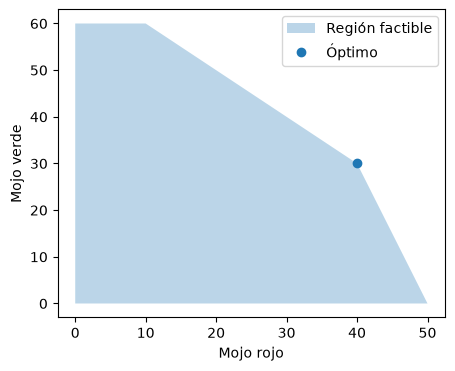

In [2]:
ganancia = np.array([5.0, 4.0])
A1 = np.array([[3, 1], [0, 2], [1, 1]], dtype=float)
b1 = np.array([150, 120, 70], dtype=float)

res = linprog(-ganancia, A_ub=A1, b_ub=b1, bounds=[(0, None)] * 2)
print(f"linprog: x = {res.x[0]:.1f} rojos, y = {res.x[1]:.1f} verdes, ganancia {-res.fun:.1f} €")

A1_total = np.vstack([A1, -np.eye(2)])
b1_total = np.concatenate([b1, [0, 0]])
vs = vertices(A1_total, b1_total)
for v in sorted(vs, key=lambda v: ganancia @ v):
    print(f"   vértice ({v[0]:5.1f}, {v[1]:5.1f}) → {ganancia @ v:6.1f} €")
mejor = max(vs, key=lambda v: ganancia @ v)
assert np.allclose(res.x, mejor) and np.allclose(res.x, [40, 30])

centro = vs.mean(axis=0)
orden = np.argsort(np.arctan2(vs[:, 1] - centro[1], vs[:, 0] - centro[0]))
fig, ax = plt.subplots(figsize=(5, 4))
ax.fill(*vs[orden].T, alpha=0.3, label="Región factible")
ax.plot(*res.x, "o", label="Óptimo")
ax.set_xlabel("Mojo rojo")
ax.set_ylabel("Mojo verde")
ax.legend()
plt.show()

## 2. Precios sombra

El precio sombra de un recurso es cuánto aumenta la ganancia óptima por cada unidad más de ese recurso. Obtenerlos de `res.ineqlin.marginals` (cambiados de signo, porque se minimizó $-$ganancia) y comprobarlos resolviendo de nuevo el problema con una unidad más de cada recurso. Explicar por qué el cilantro tiene precio sombra 0.

In [3]:
sombra = -res.ineqlin.marginals
for nombre, precio, i in zip(["pimienta (kg)", "cilantro (manojos)", "horas"], sombra, range(3)):
    b_mas = b1.copy()
    b_mas[i] += 1
    nueva = -linprog(-ganancia, A_ub=A1, b_ub=b_mas, bounds=[(0, None)] * 2).fun
    print(f"{nombre:<20} precio sombra {precio:.2f} €; ganancia con una unidad más {nueva:.1f} €")
    assert math.isclose(nueva - (-res.fun), precio, abs_tol=1e-9)
print(f"Holgura del cilantro: {res.ineqlin.residual[1]:.0f} manojos sin usar, por eso tener más no sirve de nada.")

pimienta (kg)        precio sombra 0.50 €; ganancia con una unidad más 320.5 €
cilantro (manojos)   precio sombra 0.00 €; ganancia con una unidad más 320.0 €
horas                precio sombra 3.50 €; ganancia con una unidad más 323.5 €
Holgura del cilantro: 60 manojos sin usar, por eso tener más no sirve de nada.


## 3. El problema de la dieta

Elegir cuántas raciones de 100 g de gofio, leche, plátano, queso fresco y lentejas tomar en un día para cubrir al menos 2 000 kcal, 60 g de proteína y 1 000 mg de calcio con el menor coste, sin pasar de 3 raciones de gofio, 10 de leche, 4 de plátano, 2 de queso y 4 de lentejas. Los valores nutricionales y los precios son aproximados. Resolverlo con `linprog` y comprobarlo evaluando el coste en todos los vértices del poliedro (fuerza bruta sobre las combinaciones de 5 restricciones activas).

In [4]:
alimentos = ["gofio", "leche", "plátano", "queso fresco", "lentejas"]
nutrientes = np.array([
    [370, 65, 90, 200, 115],  # kcal
    [11, 3.3, 1.1, 15, 9],  # proteína (g)
    [80, 120, 5, 450, 20],  # calcio (mg)
])
minimos = np.array([2000, 60, 1000])
precio = np.array([0.25, 0.10, 0.20, 1.00, 0.15])
maximos = np.array([3, 10, 4, 2, 4])

res = linprog(precio, A_ub=-nutrientes, b_ub=-minimos, bounds=list(zip([0] * 5, maximos)))
for nombre, raciones in zip(alimentos, res.x):
    print(f"{nombre:<13} {raciones:5.2f} raciones")
print(f"Coste: {res.fun:.3f} €; nutrientes: {nutrientes @ res.x}")

A3 = np.vstack([-nutrientes, np.eye(5), -np.eye(5)])
b3 = np.concatenate([-minimos, maximos, np.zeros(5)])
vs = vertices(A3, b3)
print(f"{len(vs)} vértices; el más barato cuesta {min(precio @ v for v in vs):.3f} €")
assert math.isclose(min(precio @ v for v in vs), res.fun, abs_tol=1e-9)

gofio          3.00 raciones
leche          6.62 raciones
plátano        0.00 raciones
queso fresco   0.00 raciones
lentejas       4.00 raciones
Coste: 2.012 €; nutrientes: [2000.           90.83076923 1113.84615385]
34 vértices; el más barato cuesta 2.012 €


## 4. Transporte entre islas

Los puertos de Santa Cruz de Tenerife y de Las Palmas disponen de 120 y 150 contenedores, y hay que llevar 50 a La Palma, 30 a La Gomera, 20 a El Hierro, 70 a Lanzarote y 60 a Fuerteventura. Con los costes por contenedor de la tabla, minimizar el coste total con `linprog` (ofertas como $\le$ y demandas como $=$). Comprobar la dualidad fuerte resolviendo el problema dual con otro `linprog` (maximizar $\sum d_j v_j + \sum s_i u_i$ con $u_i \le 0$ y $u_i + v_j \le c_{ij}$) y ver que los dos óptimos coinciden. Comprobar también que la solución sale entera sin pedirlo.

In [5]:
origenes = ["Tenerife", "Gran Canaria"]
destinos = ["La Palma", "La Gomera", "El Hierro", "Lanzarote", "Fuerteventura"]
oferta = np.array([120, 150])
demanda = np.array([50, 30, 20, 70, 60])
coste = np.array([[300, 150, 260, 520, 450], [420, 300, 380, 330, 250]], dtype=float)
m, n = coste.shape

A_oferta = np.kron(np.eye(m), np.ones(n))
A_demanda = np.kron(np.ones(m), np.eye(n))
res = linprog(coste.ravel(), A_ub=A_oferta, b_ub=oferta, A_eq=A_demanda, b_eq=demanda, bounds=(0, None))
envios = res.x.reshape(m, n)
print(f"{'':<14}" + "".join(f"{d:>14}" for d in destinos))
for origen, fila in zip(origenes, envios):
    print(f"{origen:<14}" + "".join(f"{v:>14.0f}" for v in fila))
print(f"Coste mínimo: {res.fun:,.0f} €")

# dual: variables (u_1..u_m, v_1..v_n); u_i + v_j <= c_ij
A_dual = np.hstack([A_oferta.T, A_demanda.T])
dual = linprog(-np.concatenate([oferta, demanda]), A_ub=A_dual, b_ub=coste.ravel(),
               bounds=[(None, 0)] * m + [(None, None)] * n)
print(f"Óptimo del dual: {-dual.fun:,.0f} €")
assert math.isclose(res.fun, -dual.fun)
assert np.allclose(envios, envios.round()) and np.allclose(envios.sum(axis=0), demanda)

                    La Palma     La Gomera     El Hierro     Lanzarote Fuerteventura
Tenerife                  50            30            20             0             0
Gran Canaria               0             0             0            70            60
Coste mínimo: 62,800 €
Óptimo del dual: 62,800 €


## 5. Problemas sin solución

Un programa lineal puede no tener solución porque las restricciones son incompatibles (infactible) o porque el objetivo mejora sin límite (no acotado). Construir un ejemplo de cada tipo, resolverlos con `linprog` e interpretar `status` (2 = infactible, 3 = no acotado). Comprobar la infactibilidad sumando restricciones y la no acotación encontrando una dirección factible en la que el objetivo crece.

In [6]:
# x + y <= 4 y x + y >= 6 a la vez
infactible = linprog([1, 1], A_ub=[[1, 1], [-1, -1]], b_ub=[4, -6], bounds=[(0, None)] * 2)
print(f"status {infactible.status}: {infactible.message}")
assert infactible.status == 2
assert 4 + (-6) < 0  # sumar las dos filas da 0 <= -2

# maximizar x + y con solo x - y <= 2
no_acotado = linprog([-1, -1], A_ub=[[1, -1]], b_ub=[2], bounds=[(0, None)] * 2)
print(f"status {no_acotado.status}: {no_acotado.message}")
assert no_acotado.status == 3
direccion = np.array([1.0, 1.0])
assert np.array([1, -1]) @ direccion <= 0 and np.array([1, 1]) @ direccion > 0

status 2: The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)
status 3: The problem is unbounded. (HiGHS Status 10: model_status is Unbounded; primal_status is Feasible)


## 6. Mochila con `milp`

Para una excursión al Roque Nublo, elegir qué objetos llevar en una mochila de 9 kg maximizando su utilidad (cada objeto entero o nada). Plantearlo como programa entero con variables binarias y resolverlo con `scipy.optimize.milp`. Comprobarlo con fuerza bruta sobre los $2^{10}$ subconjuntos y comparar con la relajación lineal (variables entre 0 y 1), que da una cota superior.

In [7]:
objetos = ["agua", "bocadillos", "chaqueta", "cámara", "botiquín", "linterna", "prismáticos", "libro", "fruta", "toalla"]
peso = np.array([3, 2, 2, 1.5, 1, 0.5, 1.2, 0.8, 1.5, 1.4])
utilidad = np.array([10, 8, 6, 5, 7, 3, 4, 1, 4, 2])
CAPACIDAD = 9

res = milp(-utilidad, constraints=LinearConstraint(peso, ub=CAPACIDAD), integrality=np.ones(10), bounds=Bounds(0, 1))
elegidos = res.x.round().astype(bool)
print("milp:", [o for o, e in zip(objetos, elegidos) if e], f"utilidad {-res.fun:.0f}, peso {peso @ elegidos:.1f} kg")

mejor = max(
    (sel for sel in itertools.product([0, 1], repeat=10) if peso @ sel <= CAPACIDAD),
    key=lambda sel: utilidad @ sel,
)
relajada = linprog(-utilidad, A_ub=[peso], b_ub=[CAPACIDAD], bounds=(0, 1))
print(f"Fuerza bruta: {utilidad @ mejor}; relajación lineal: {-relajada.fun:.2f}")
assert utilidad @ mejor == -res.fun <= -relajada.fun

milp: ['agua', 'bocadillos', 'cámara', 'botiquín', 'prismáticos'] utilidad 34, peso 8.7 kg
Fuerza bruta: 34; relajación lineal: 36.33


## 7. Ramificación y acotación a mano

Resolver la mochila con ramificación y acotación: recorrer en profundidad el árbol de decisiones (coger o no cada objeto, ordenados por utilidad por kilo) y podar una rama cuando su cota, la mochila fraccionaria con los objetos restantes, no supera la mejor solución encontrada. Contar los nodos visitados y comparar el resultado con `milp` en la mochila anterior y en una de 30 objetos aleatorios (semilla fija), donde la fuerza bruta tendría $2^{30}$ casos.

In [8]:
def mochila_ramificacion(peso, utilidad, capacidad):
    orden = sorted(range(len(peso)), key=lambda i: -utilidad[i] / peso[i])
    p = [float(peso[i]) for i in orden]
    u = [float(utilidad[i]) for i in orden]
    mejor = {"valor": 0.0, "seleccion": []}
    nodos = 0

    def cota(i, capacidad_libre, valor):
        for j in range(i, len(p)):
            if p[j] <= capacidad_libre:
                capacidad_libre -= p[j]
                valor += u[j]
            else:
                return valor + u[j] * capacidad_libre / p[j]
        return valor

    def explorar(i, capacidad_libre, valor, seleccion):
        nonlocal nodos
        nodos += 1
        if valor > mejor["valor"]:
            mejor.update(valor=valor, seleccion=seleccion)
        if i == len(p) or cota(i, capacidad_libre, valor) <= mejor["valor"]:
            return
        if p[i] <= capacidad_libre:
            explorar(i + 1, capacidad_libre - p[i], valor + u[i], seleccion + [orden[i]])
        explorar(i + 1, capacidad_libre, valor, seleccion)

    explorar(0, capacidad, 0.0, [])
    return mejor["valor"], sorted(mejor["seleccion"]), nodos


valor, seleccion, nodos = mochila_ramificacion(peso, utilidad, CAPACIDAD)
print(f"10 objetos: utilidad {valor:.0f} visitando {nodos} nodos de {2**11 - 1}")
assert math.isclose(valor, -res.fun) and utilidad[seleccion].sum() == valor and peso[seleccion].sum() <= CAPACIDAD

rng = np.random.default_rng(41)
peso30 = rng.integers(1, 20, 30).astype(float)
utilidad30 = rng.integers(1, 30, 30).astype(float)
cap30 = peso30.sum() / 3
valor30, _, nodos30 = mochila_ramificacion(peso30, utilidad30, cap30)
res30 = milp(-utilidad30, constraints=LinearConstraint(peso30, ub=cap30), integrality=np.ones(30), bounds=Bounds(0, 1))
print(f"30 objetos: utilidad {valor30:.0f} (milp {-res30.fun:.0f}) visitando {nodos30:,} nodos de {2**31 - 1:,}")
assert math.isclose(valor30, -res30.fun)

10 objetos: utilidad 34 visitando 57 nodos de 2047
30 objetos: utilidad 285 (milp 285) visitando 47 nodos de 2,147,483,647


## 8. Redondear no basta

Una empresa de alquiler en Fuerteventura gana 21 € por furgoneta ($x$) y 11 € por moto ($y$) al día, y el espacio del garaje impone $7x + 4y \le 13$. Resolver la relajación lineal, redondear su solución hacia abajo y comparar con el óptimo entero de `milp` y con una búsqueda por fuerza bruta en la rejilla de enteros factibles. Mostrar que el óptimo entero no está cerca de la solución lineal.

In [9]:
c8 = np.array([21, 11])
lineal = linprog(-c8, A_ub=[[7, 4]], b_ub=[13], bounds=[(0, None)] * 2)
redondeo = np.floor(lineal.x)
entero = milp(-c8, constraints=LinearConstraint([[7, 4]], ub=13), integrality=[1, 1], bounds=Bounds(0, np.inf))
bruta = max(((x, y) for x in range(3) for y in range(5) if 7 * x + 4 * y <= 13), key=lambda p: c8 @ p)

print(f"Lineal:     {lineal.x.round(3)} → {-lineal.fun:.2f} €")
print(f"Redondeada: {redondeo} → {c8 @ redondeo:.0f} €")
print(f"Entera:     {entero.x.round()} → {-entero.fun:.0f} €; fuerza bruta {bruta} → {c8 @ bruta} €")
assert np.allclose(entero.x, bruta) and -entero.fun == c8 @ bruta > c8 @ redondeo

Lineal:     [1.857 0.   ] → 39.00 €
Redondeada: [1. 0.] → 21 €
Entera:     [0. 3.] → 33 €; fuerza bruta (0, 3) → 33 €


## 9. Asignación de socorristas

Asignar cinco socorristas a cinco playas de Gran Canaria, uno por playa, minimizando la suma de los minutos de desplazamiento de la tabla. Resolverlo con `scipy.optimize.linear_sum_assignment` (algoritmo húngaro), comprobarlo con las $5! = 120$ permutaciones y con `milp` usando 25 variables binarias con una restricción por fila y otra por columna.

In [10]:
socorristas = ["Ana", "Borja", "Carla", "Dácil", "Eloy"]
playas = ["Las Canteras", "Las Alcaravaneras", "Maspalomas", "Puerto de Mogán", "Sardina"]
minutos = np.array([
    [10, 15, 45, 60, 35],
    [20, 8, 40, 55, 40],
    [50, 45, 12, 25, 70],
    [55, 50, 20, 10, 75],
    [30, 35, 60, 70, 15],
])

filas, columnas = optimize.linear_sum_assignment(minutos)
total = minutos[filas, columnas].sum()
for i, j in zip(filas, columnas):
    print(f"{socorristas[i]:<6} → {playas[j]:<18} {minutos[i, j]} min")
print("Total:", total, "min")

bruta = min(sum(minutos[i, p[i]] for i in range(5)) for p in itertools.permutations(range(5)))
restricciones = LinearConstraint(np.vstack([np.kron(np.eye(5), np.ones(5)), np.kron(np.ones(5), np.eye(5))]), 1, 1)
binaria = milp(minutos.ravel(), constraints=restricciones, integrality=np.ones(25), bounds=Bounds(0, 1))
assert total == bruta == round(binaria.fun)

Ana    → Las Canteras       10 min
Borja  → Las Alcaravaneras  8 min
Carla  → Maspalomas         12 min
Dácil  → Puerto de Mogán    10 min
Eloy   → Sardina            15 min
Total: 55 min


## 10. El viajante exacto

Calcular la distancia por círculo máximo (fórmula del semiverseno) entre las siete capitales insulares, Caleta de Sebo (La Graciosa) y Puerto de la Cruz, con coordenadas aproximadas, y encontrar la ruta circular más corta que sale de Santa Cruz de Tenerife y visita todas una vez, probando las $8! = 40\,320$ permutaciones del resto. Comprobar que la ruta inversa mide lo mismo.

In [11]:
CIUDADES = {
    "Santa Cruz de Tenerife": (28.46, -16.25),
    "Las Palmas": (28.12, -15.43),
    "Arrecife": (28.96, -13.55),
    "Puerto del Rosario": (28.50, -13.86),
    "San Sebastián": (28.09, -17.11),
    "Santa Cruz de La Palma": (28.68, -17.77),
    "Valverde": (27.81, -17.91),
    "Caleta de Sebo": (29.23, -13.50),
    "Puerto de la Cruz": (28.41, -16.55),
}
nombres = list(CIUDADES)


def semiverseno(a, b, radio=6371.0):
    (la1, lo1), (la2, lo2) = (map(math.radians, p) for p in (a, b))
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * radio * math.asin(math.sqrt(h))


D = np.array([[semiverseno(CIUDADES[a], CIUDADES[b]) for b in nombres] for a in nombres])


def longitud(ruta, D=D):
    return sum(D[a, b] for a, b in zip(ruta, ruta[1:] + ruta[:1]))


mejor_ruta = min(([0, *p] for p in itertools.permutations(range(1, len(nombres)))), key=longitud)
optimo_tsp = longitud(mejor_ruta)
print(" → ".join(nombres[i] for i in mejor_ruta))
print(f"Longitud: {optimo_tsp:.1f} km")
assert math.isclose(longitud([0, *mejor_ruta[:0:-1]]), optimo_tsp)

Santa Cruz de Tenerife → Caleta de Sebo → Arrecife → Puerto del Rosario → Las Palmas → San Sebastián → Valverde → Santa Cruz de La Palma → Puerto de la Cruz


Longitud: 1030.2 km


## 11. Recocido simulado

El recocido simulado parte de una ruta al azar y propone cambios pequeños (invertir un tramo, el movimiento 2-opt). Acepta siempre los que acortan la ruta y los que la alargan en $\Delta$ con probabilidad $e^{-\Delta / T}$, donde la temperatura $T$ baja poco a poco. Escribir `recocido(D, semilla)` con enfriamiento geométrico y comprobar que, con `random.Random(42)`, encuentra la ruta óptima del ejercicio anterior. Probar 20 semillas y contar cuántas veces acierta.

In [12]:
def recocido(D, semilla, T0=200.0, enfriamiento=0.999, pasos=20_000):
    rng = random.Random(semilla)
    n = len(D)
    ruta = list(range(n))
    rng.shuffle(ruta)
    actual = longitud(ruta, D)
    mejor, mejor_ruta = actual, ruta[:]
    T = T0
    for _ in range(pasos):
        i, j = sorted(rng.sample(range(n), 2))
        nueva = ruta[:i] + ruta[i : j + 1][::-1] + ruta[j + 1 :]
        delta = longitud(nueva, D) - actual
        if delta < 0 or rng.random() < math.exp(-delta / T):
            ruta, actual = nueva, actual + delta
            if actual < mejor - 1e-9:
                mejor, mejor_ruta = actual, ruta[:]
        T *= enfriamiento
    return mejor, mejor_ruta


valor, ruta = recocido(D, 42)
print(f"Recocido (semilla 42): {valor:.1f} km; óptimo {optimo_tsp:.1f} km")
assert math.isclose(valor, optimo_tsp)
aciertos = sum(math.isclose(recocido(D, s)[0], optimo_tsp) for s in range(20))
print(f"Aciertos con 20 semillas: {aciertos}/20")

Recocido (semilla 42): 1030.2 km; óptimo 1030.2 km


Aciertos con 20 semillas: 20/20


## 12. Recocido frente a una heurística voraz

Con 60 puntos al azar en el cuadrado unidad (semilla fija), donde la búsqueda exhaustiva es imposible, comparar tres rutas: la del vecino más próximo, esa misma mejorada con 2-opt hasta que ningún cambio la acorte (un óptimo local) y la del recocido simulado. Comprobar que 2-opt nunca empeora la ruta voraz y que la ruta de cada método visita cada punto exactamente una vez. ¿Cuál gana con 40 000 pasos de recocido? Dibujar la mejor ruta.

vecino más próximo   8.210
+ 2-opt              6.373
recocido             6.666


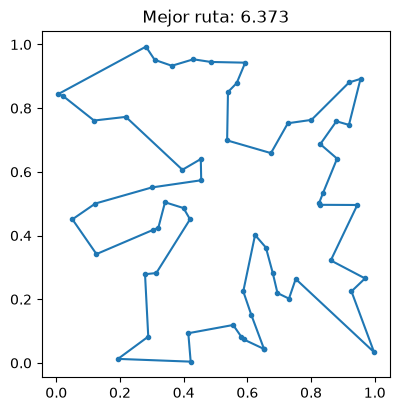

In [13]:
rng = np.random.default_rng(43)
puntos = rng.random((60, 2))
D60 = np.linalg.norm(puntos[:, None] - puntos[None], axis=2)


def vecino_mas_proximo(D):
    ruta, libres = [0], set(range(1, len(D)))
    while libres:
        siguiente = min(libres, key=lambda j: D[ruta[-1], j])
        ruta.append(siguiente)
        libres.remove(siguiente)
    return ruta


def dos_opt(ruta, D):
    ruta = ruta[:]
    mejora = True
    while mejora:
        mejora = False
        for i in range(1, len(ruta) - 1):
            for j in range(i + 1, len(ruta)):
                a, b, c, d = ruta[i - 1], ruta[i], ruta[j], ruta[(j + 1) % len(ruta)]
                if D[a, c] + D[b, d] < D[a, b] + D[c, d] - 1e-12:
                    ruta[i : j + 1] = ruta[i : j + 1][::-1]
                    mejora = True
    return ruta


voraz = vecino_mas_proximo(D60)
local = dos_opt(voraz, D60)
valor_sa, ruta_sa = recocido(D60, 7, T0=1.0, enfriamiento=0.9997, pasos=40_000)
for nombre, r in [("vecino más próximo", voraz), ("+ 2-opt", local), ("recocido", ruta_sa)]:
    print(f"{nombre:<20} {longitud(r, D60):.3f}")
    assert sorted(r) == list(range(60))
assert longitud(local, D60) <= longitud(voraz, D60)
assert math.isclose(valor_sa, longitud(ruta_sa, D60))

mejor = min([local, ruta_sa], key=lambda r: longitud(r, D60))
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(*puntos[mejor + mejor[:1]].T, "o-", markersize=3)
ax.set_title(f"Mejor ruta: {longitud(mejor, D60):.3f}")
ax.set_aspect("equal")
plt.show()

## 13. Recocido en una función continua

La función de Rastrigin $f(x) = 10n + \sum_i \left(x_i^2 - 10\cos(2\pi x_i)\right)$ tiene un mínimo global 0 en el origen rodeado de muchos mínimos locales. Desde $(4{,}5;\ 4{,}5)$, comprobar que `minimize` (BFGS) se queda en un mínimo local; después minimizarla con un recocido propio (pasos gaussianos con semilla fija, refinado al final con `minimize`) y con `optimize.dual_annealing` (con `rng` fijo) y comprobar que ambos llegan al origen.

In [14]:
def rastrigin(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))


inicio = np.array([4.5, 4.5])
local = optimize.minimize(rastrigin, inicio, method="BFGS")
print(f"BFGS: {local.x.round(4)}, f = {local.fun:.4f}")
assert local.fun > 1


def recocido_continuo(f, x0, semilla, T0=10.0, enfriamiento=0.999, pasos=10_000, escala=0.5):
    rng = np.random.default_rng(semilla)
    x, fx = np.array(x0, dtype=float), f(x0)
    mejor, f_mejor = x.copy(), fx
    T = T0
    for _ in range(pasos):
        candidato = x + rng.normal(0, escala, x.size)
        fc = f(candidato)
        if fc < fx or rng.random() < math.exp(-(fc - fx) / T):
            x, fx = candidato, fc
            if fx < f_mejor:
                mejor, f_mejor = x.copy(), fx
        T *= enfriamiento
    return optimize.minimize(f, mejor, method="BFGS").x


x_sa = recocido_continuo(rastrigin, inicio, 44)
da = optimize.dual_annealing(rastrigin, bounds=[(-5.12, 5.12)] * 2, x0=inicio, rng=np.random.default_rng(45))
print(f"Recocido propio: {(x_sa.round(6) + 0.0)}, f = {rastrigin(x_sa):.2e}")
print(f"dual_annealing:  {(da.x.round(6) + 0.0)}, f = {da.fun:.2e}")
assert rastrigin(x_sa) < 1e-8 and da.fun < 1e-8

BFGS: [3.9798 3.9798], f = 31.8385
Recocido propio: [0. 0.], f = 2.13e-14
dual_annealing:  [0. 0.], f = 1.07e-14
